# Recuperación para RAG: qué importa de verdad y cómo medirlo

**Perfil:** IA y automatización  
**Datos:** corpus real (113 documentos Markdown del repositorio, congelado en `datos/corpus_snapshot.json`); consultas sintéticas generadas con verdad conocida.

## Pregunta que guía el notebook

Antes de que un LLM responda, un sistema RAG debe **encontrar** el pasaje correcto. Casi todas las decisiones de diseño (cómo partir los documentos, qué índice usar, cómo combinar rankings, cuánto contexto empaquetar) se toman por intuición. ¿Cuánto vale cada una **medida con rigor** (intervalos, pruebas pareadas, potencia) sobre un corpus real y con consultas de verdad conocida?

## Recorrido

1. Corpus **real**: los 113 documentos Markdown de este repositorio (README, notas técnicas), con casi-duplicados reales (familias de proyectos con la misma plantilla).
2. Un conjunto de 600 consultas con verdad conocida en cuatro tipos (encabezado, palabras clave, mixta, con errores tipográficos) y su **ambigüedad** medida.
3. **Normalización de texto**: tildes, *stemming*, palabras vacías.
4. **Fragmentación** (*chunking*): ventanas fijas, con solape, por encabezado y por oraciones; efecto en el ranking y en la **cobertura de la respuesta** con un presupuesto de contexto.
5. **BM25**: sensibilidad a $k_1$ y $b$ con validación separada por documento (sin fuga).
6. **Cinco recuperadores** (BM25, TF-IDF, LSA, trigramas de caracteres, híbridos con RRF y ponderados) con IC bootstrap y **pruebas de permutación pareadas** con corrección por comparaciones múltiples.
7. **Análisis por tipo de consulta y por ambigüedad**, y errores que son casi-duplicados.
8. **Empaquetado de contexto** con presupuesto y diversidad (MMR).
9. **Potencia estadística**: qué diferencias se pueden detectar con n consultas.
10. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
import sys, json, time, itertools
sys.path.insert(0, "src")
from collections import Counter
from scipy import stats
from ragkit import text as T, chunking as CH, indexes as IX, fusion as FU, metrics as ME, queries as QU, evaluate as EV
from ragkit.chunking import Doc

## 2. El corpus y sus casi-duplicados

El corpus es el propio repositorio: documentos de dominios distintos (riesgo, cuantitativo, estrategia, datos) en español con términos en inglés. Tiene una propiedad realista y exigente: **familias de documentos con la misma plantilla** (por ejemplo, los README de 15 motores de decisión). Para una consulta, varios documentos pueden ser casi igual de buenos; se mide ese solapamiento con el coseno TF-IDF entre documentos.

113 documentos, 26,608 palabras; mediana 192 palabras por documento (min 44, max 773)
06-strategy-innovation-and-leadership    59
03-financial-risk                        34
02-mathematics-statistics-and-quant       9
04-quant-strategy-and-products            8
(raiz)                                    2
01-economics-and-econometrics             1

Coseno con el documento mas parecido: mediana 0.34; 40 documentos con vecino > 0.5; 2 con vecino > 0.8


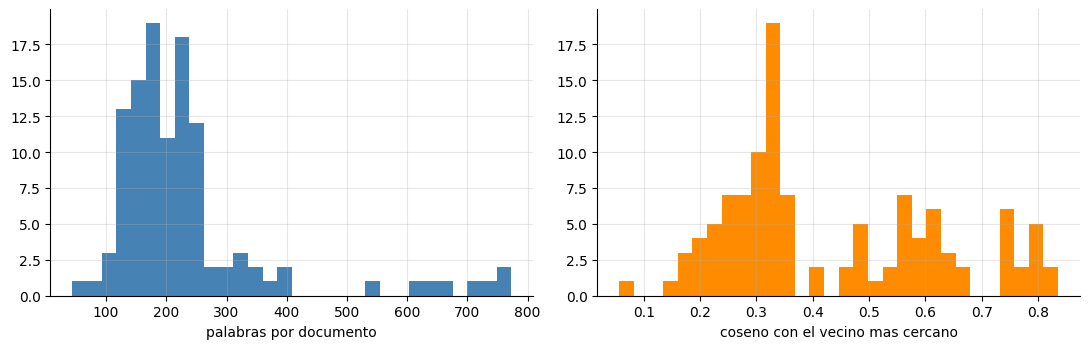

In [2]:
snap = json.load(open("datos/corpus_snapshot.json")); docs = [Doc(k, v) for k, v in snap.items()]
dominio = pd.Series([d.id.split("/")[0] if "/" in d.id else "(raiz)" for d in docs]); palabras = pd.Series([len(d.text.split()) for d in docs])
print(f"{len(docs)} documentos, {palabras.sum():,} palabras; mediana {int(palabras.median())} palabras por documento (min {palabras.min()}, max {palabras.max()})")
print(dominio.value_counts().to_string())
tfd = IX.TfIdf([d.text for d in docs]); S = tfd.X @ tfd.X.T; S = S.toarray(); np.fill_diagonal(S, 0)
vecino = S.max(axis=1); por_doc = pd.Series(vecino, index=[d.id for d in docs])
print(f"\nCoseno con el documento mas parecido: mediana {np.median(vecino):.2f}; {int((vecino > 0.5).sum())} documentos con vecino > 0.5; {int((vecino > 0.8).sum())} con vecino > 0.8")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); ax[0].hist(palabras, bins=30, color="steelblue"); ax[0].set_xlabel("palabras por documento"); ax[1].hist(vecino, bins=30, color="darkorange"); ax[1].set_xlabel("coseno con el vecino mas cercano"); plt.tight_layout(); plt.show()

In [3]:
print("Lectura:")
print(f"  El corpus es chico (≈{palabras.sum() / 1000:.0f}k palabras) pero adverso: {int((vecino > 0.5).sum())} de {len(docs)} documentos tienen un casi-duplicado (coseno > 0.5). Distinguir entre ellos exige terminos especificos, no solo el tema.")
print(f"  Documentos mas cortos de 100 palabras: {int((palabras < 100).sum())}; mas largos de 1.000: {int((palabras > 1000).sum())} (la longitud afecta a la normalizacion de BM25).")

Lectura:
  El corpus es chico (≈27k palabras) pero adverso: 40 de 113 documentos tienen un casi-duplicado (coseno > 0.5). Distinguir entre ellos exige terminos especificos, no solo el tema.
  Documentos mas cortos de 100 palabras: 2; mas largos de 1.000: 0 (la longitud afecta a la normalizacion de BM25).


## 3. Las consultas y su ambigüedad

Cada consulta se genera desde una **sección** de un documento (la verdad es ese documento) en cuatro tipos:

| tipo | cómo se construye | qué mide |
|---|---|---|
| `heading` | el encabezado de la sección | caso fácil léxico (pero hay encabezados genéricos repetidos) |
| `keyword` | 3 términos raros del pasaje, **sin** palabras del título, de la ruta ni del encabezado | recuperar por contenido |
| `mixed` | 2 palabras del encabezado + 2 del pasaje | consulta natural |
| `typo` | como `keyword` pero con errores tipográficos en la mitad de los términos | robustez |

La **ambigüedad** `n_cand` es el número de documentos que contienen *todos* los términos de la consulta: si es 1, solo hay una respuesta posible; si es 6, hay seis documentos que satisfacen la consulta literalmente. Es el techo natural de cualquier recuperador léxico.

In [4]:
NQ = 600; qs = QU.make_queries(docs, NQ, seed=7)
dq = pd.DataFrame([{"qid": q.id, "kind": q.kind, "n_cand": q.n_cand, "texto": q.text, "gold": q.gold_doc} for q in qs])
print(dq.groupby("kind").agg(n=("qid", "size"), ambiguedad_mediana=("n_cand", "median"), unica_respuesta=("n_cand", lambda x: (x == 1).mean()), techo_hit1_aleatorio=("n_cand", lambda x: (1 / x).mean())).round(3).to_string())
print("\nEjemplos:"); print(dq.groupby("kind").head(2)[["kind", "texto", "n_cand"]].to_string(index=False))

           n  ambiguedad_mediana  unica_respuesta  techo_hit1_aleatorio
kind                                                                   
heading  150              3.5000           0.3000                0.4220
keyword  150              1.0000           0.5800                0.6490
mixed    150              1.0000           0.6600                0.7300
typo     150              1.0000           0.7000                0.7580

Ejemplos:
   kind                                                  texto  n_cand
heading                                   Resultado de ejemplo      50
keyword                          productiva parametrica causal       5
  mixed                    ead comparacion reconocer precision       1
   typo                             coherente outflows funding       1
heading Migración ejecutada: rutas anteriores → rutas actuales       1
keyword                            estudiar bidask precedencia       1
  mixed            investigacion minimo experiments benchmar

In [5]:
print("Lectura:")
print(f"  Solo el {(dq.n_cand == 1).mean():.0%} de las consultas tiene una unica respuesta literal posible. Si el sistema eligiera al azar entre los candidatos, su acierto en la posicion 1 seria ≈{(1 / dq.n_cand).mean():.0%}: es la referencia 'sin informacion de ranking', no un techo (los mejores rankings usan frecuencias para desempatar).")
print(f"  Las consultas 'heading' son las mas ambiguas (mediana {dq[dq.kind == 'heading'].n_cand.median():.0f} documentos candidatos): encabezados como 'Validacion y limites' aparecen en decenas de documentos de la misma plantilla.")

Lectura:
  Solo el 56% de las consultas tiene una unica respuesta literal posible. Si el sistema eligiera al azar entre los candidatos, su acierto en la posicion 1 seria ≈64%: es la referencia 'sin informacion de ranking', no un techo (los mejores rankings usan frecuencias para desempatar).
  Las consultas 'heading' son las mas ambiguas (mediana 4 documentos candidatos): encabezados como 'Validacion y limites' aparecen en decenas de documentos de la misma plantilla.


## 4. Normalización de texto

Tres decisiones antes de indexar: quitar **tildes** (¿"estimación" = "estimacion"?), aplicar **stemming** ligero y descartar **palabras vacías**. Se mide cada combinación con BM25 y fragmentación por encabezado (200 palabras), con **IC bootstrap del 95 %** sobre las 600 consultas. La métrica es el **rango recíproco medio (MRR)** del documento verdadero, agregando fragmentos a documento por el mejor fragmento.

In [6]:
chunks_h = CH.chunk_corpus(docs, CH.by_heading, max_words=200); texts_h = [c.text for c in chunks_h]
def mrr_vec(df, method): return df[df.method == method].sort_values("qid")["mrr"].values
def correr(builder, chunks, queries=qs, **kw):
    ix = builder([c.text for c in chunks], **kw); return EV.evaluate({"m": ix.scores}, chunks, queries)
filas = []
for acc, st, sw in itertools.product([True, False], [True, False], [True, False]):
    d = correr(IX.BM25, chunks_h, accents=acc, stemming=st, stop=sw); v = d["mrr"].values; m, lo, hi = ME.bootstrap_ci(v)
    filas.append({"tildes_plegadas": acc, "stemming": st, "sin_vacias": sw, "MRR": m, "IC95_lo": lo, "IC95_hi": hi, "hit@5": d["hit@5"].mean()})
norm = pd.DataFrame(filas).sort_values("MRR", ascending=False).reset_index(drop=True); norm.round(3)

,tildes_plegadas,stemming,sin_vacias,MRR,IC95_lo,IC95_hi,hit@5
0,True,False,False,0.7160,0.6830,0.7480,0.8320
1,True,False,True,0.7140,0.6830,0.7460,0.8320
2,True,True,False,0.7090,0.6780,0.7420,0.8300
3,True,True,True,0.7080,0.6770,0.7410,0.8300
4,False,False,True,0.6870,0.6540,0.7200,0.8030
5,False,False,False,0.6790,0.6470,0.7120,0.8000
6,False,True,True,0.6780,0.6460,0.7110,0.8000
7,False,True,False,0.6760,0.6440,0.7080,0.7970


In [7]:
mejor = norm.iloc[0]; v_mejor = correr(IX.BM25, chunks_h, accents=bool(mejor.tildes_plegadas), stemming=bool(mejor.stemming), stop=bool(mejor.sin_vacias))["mrr"].values
pv = []
for _, r in norm.iterrows():
    v = correr(IX.BM25, chunks_h, accents=bool(r.tildes_plegadas), stemming=bool(r.stemming), stop=bool(r.sin_vacias))["mrr"].values
    pv.append(ME.paired_permutation_test(v_mejor, v, B=4000, seed=1) if not np.array_equal(v, v_mejor) else 1.0)
norm["p_vs_mejor"] = pv
def holm_ajuste(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r_, i in enumerate(o): run = max(run, min(1.0, (m - r_) * p[i])); adj[i] = run
    return adj
norm["p_Holm"] = np.r_[1.0, holm_ajuste(norm.p_vs_mejor.values[1:])]; norm.round(4)

,tildes_plegadas,stemming,sin_vacias,MRR,IC95_lo,IC95_hi,hit@5,p_vs_mejor,p_Holm
0,True,False,False,0.7156,0.6834,0.7477,0.8317,1.0000,1.0000
1,True,False,True,0.7137,0.6825,0.7457,0.8317,0.5571,0.5571
2,True,True,False,0.7093,0.6778,0.7418,0.8300,0.0785,0.2354
3,True,True,True,0.7078,0.6765,0.7408,0.8300,0.1285,0.2569
4,False,False,True,0.6867,0.6545,0.7197,0.8033,0.0002,0.0017
5,False,False,False,0.6793,0.6471,0.7121,0.8000,0.0002,0.0017
6,False,True,True,0.6781,0.6462,0.7114,0.8000,0.0002,0.0017
7,False,True,False,0.6757,0.6442,0.7083,0.7967,0.0002,0.0017


In [8]:
peor = norm.iloc[-1]; indist = norm.iloc[1:][norm.iloc[1:].p_Holm > 0.05]
print("Lectura:")
print(f"  Mejor: tildes={mejor.tildes_plegadas}, stemming={mejor.stemming}, sin vacias={mejor.sin_vacias} (MRR {mejor.MRR:.3f}); peor: tildes={peor.tildes_plegadas}, stemming={peor.stemming}, sin vacias={peor.sin_vacias} ({peor.MRR:.3f}).")
print(f"  Con prueba pareada y correccion de Holm, {len(indist)} de las otras 7 configuraciones NO se distinguen de la mejor (p_Holm > 0.05).")
for col in ("tildes_plegadas", "stemming", "sin_vacias"):
    g = norm.groupby(col).MRR.mean(); print(f"  Efecto marginal de {col}: {g.get(True, np.nan) - g.get(False, np.nan):+.3f} de MRR (promedio sobre las demas decisiones).")
print("  Plegar tildes ayuda porque el tokenizador ascii parte las palabras con tilde ('estimacion' -> 'estimaci','n') si no se pliegan: es una decision de correccion mas que de ajuste fino. El stemming ligero no mejora aqui; quitar palabras vacias casi no cambia el ranking de BM25 (el idf ya las penaliza).")
TOK = dict(accents=True, stemming=False, stop=True)          # configuracion base elegida: simple y sin diferencia significativa frente a la mejor

Lectura:
  Mejor: tildes=True, stemming=False, sin vacias=False (MRR 0.716); peor: tildes=False, stemming=True, sin vacias=False (0.676).
  Con prueba pareada y correccion de Holm, 3 de las otras 7 configuraciones NO se distinguen de la mejor (p_Holm > 0.05).
  Efecto marginal de tildes_plegadas: +0.032 de MRR (promedio sobre las demas decisiones).
  Efecto marginal de stemming: -0.006 de MRR (promedio sobre las demas decisiones).
  Efecto marginal de sin_vacias: +0.002 de MRR (promedio sobre las demas decisiones).
  Plegar tildes ayuda porque el tokenizador ascii parte las palabras con tilde ('estimacion' -> 'estimaci','n') si no se pliegan: es una decision de correccion mas que de ajuste fino. El stemming ligero no mejora aqui; quitar palabras vacias casi no cambia el ranking de BM25 (el idf ya las penaliza).


## 5. Fragmentación: ¿cuánto y cómo partir?

Se comparan 10 estrategias con BM25. Dos métricas: el **MRR** del documento verdadero y la **cobertura de la respuesta**: se empaqueta el contexto con los mejores fragmentos *distintos* hasta un presupuesto de 300 palabras y se mide la fracción de consultas cuyo **hecho** (un número o término raro de la sección de origen) aparece en el contexto. Es la métrica que más se parece a lo que le importa al generador: ¿llegó la información necesaria?

In [9]:
ESTRATEGIAS = {"fija 64": (CH.fixed, dict(size=64, overlap=0)), "fija 128": (CH.fixed, dict(size=128, overlap=0)), "fija 256": (CH.fixed, dict(size=256, overlap=0)), "fija 128 solape 32": (CH.fixed, dict(size=128, overlap=32)),
               "fija 128 solape 64": (CH.fixed, dict(size=128, overlap=64)), "encabezado 100": (CH.by_heading, dict(max_words=100)), "encabezado 200": (CH.by_heading, dict(max_words=200)), "encabezado 400": (CH.by_heading, dict(max_words=400)),
               "oraciones 60": (CH.sentences, dict(max_words=60)), "oraciones 120": (CH.sentences, dict(max_words=120))}
BUDGET = 300
def cobertura(ix_scores, chunks, queries, budget=BUDGET):
    ok = []
    for q in queries:
        s = ix_scores(q.text); idx = np.lexsort((np.arange(len(s)), -s))[:30]; idx = [i for i in idx if s[i] > 0]
        ok.append(EV.answer_coverage(EV.pack_context(idx, chunks, budget), q.fact) if q.fact else np.nan)
    return np.array(ok, float)
filas = []; frag = {}
for nombre, (fn_, kw) in ESTRATEGIAS.items():
    ch = CH.chunk_corpus(docs, fn_, **kw); ix = IX.BM25([c.text for c in ch], **TOK); d = EV.evaluate({"m": ix.scores}, ch, qs); cov = cobertura(ix.scores, ch, qs)
    frag[nombre] = (ch, ix); w = np.array([len(c.text.split()) for c in ch])
    filas.append({"estrategia": nombre, "fragmentos": len(ch), "palabras_medias": w.mean(), "MRR_doc": d.mrr.mean(), "hit@5": d["hit@5"].mean(), f"cobertura_respuesta@{BUDGET}": np.nanmean(cov), "nnz_indice": ix.W.nnz})
chk = pd.DataFrame(filas).set_index("estrategia"); chk.round(3)

,fragmentos,palabras_medias,MRR_doc,hit@5,cobertura_respuesta@300,nnz_indice
estrategia,,,,,,
fija 64,467,56.9760,0.6840,0.8300,0.7250,16403
fija 128,265,100.4080,0.7000,0.8250,0.7880,15554
fija 256,148,179.7840,0.7110,0.8150,0.8520,14616
fija 128 solape 32,306,107.1370,0.7040,0.8250,0.8570,19248
fija 128 solape 64,355,118.5800,0.6960,0.8200,0.8520,24682
encabezado 100,709,37.5290,0.7180,0.8300,0.9150,16303
encabezado 200,675,39.4190,0.7140,0.8320,0.9250,16144
encabezado 400,665,40.0120,0.7120,0.8320,0.9270,16098
oraciones 60,546,48.7330,0.7080,0.8430,0.7380,16432


In [10]:
col = f"cobertura_respuesta@{BUDGET}"; b1 = chk.MRR_doc.idxmax(); b2 = chk[col].idxmax()
print("Lectura:")
print(f"  Mejor MRR de documento: '{b1}' ({chk.loc[b1, 'MRR_doc']:.3f}); mejor cobertura de la respuesta con {BUDGET} palabras: '{b2}' ({chk.loc[b2, col]:.3f}). Rango de MRR entre estrategias: {chk.MRR_doc.min():.3f}-{chk.MRR_doc.max():.3f}; de cobertura: {chk[col].min():.3f}-{chk[col].max():.3f}.")
print(f"  Correlacion entre palabras medias por fragmento y cobertura: {np.corrcoef(chk.palabras_medias, chk[col])[0, 1]:+.2f}; entre palabras medias y MRR: {np.corrcoef(chk.palabras_medias, chk.MRR_doc)[0, 1]:+.2f}.")
print(f"  Solape: fija 128 sin solape {chk.loc['fija 128', 'MRR_doc']:.3f} -> solape 32 {chk.loc['fija 128 solape 32', 'MRR_doc']:.3f} -> solape 64 {chk.loc['fija 128 solape 64', 'MRR_doc']:.3f}; el indice crece {chk.loc['fija 128 solape 64', 'nnz_indice'] / chk.loc['fija 128', 'nnz_indice']:.1f}x con solape de 50%.")

Lectura:
  Mejor MRR de documento: 'encabezado 100' (0.718); mejor cobertura de la respuesta con 300 palabras: 'encabezado 400' (0.927). Rango de MRR entre estrategias: 0.684-0.718; de cobertura: 0.725-0.927.
  Correlacion entre palabras medias por fragmento y cobertura: -0.12; entre palabras medias y MRR: -0.18.
  Solape: fija 128 sin solape 0.700 -> solape 32 0.704 -> solape 64 0.696; el indice crece 1.6x con solape de 50%.


In [11]:
ok_ = chk[chk.MRR_doc >= chk.MRR_doc.max() - 0.01]; BASE_CH = ok_[col].idxmax(); chunks_b, bm_b = frag[BASE_CH]
print(f"Fragmentacion base elegida por regla (mejor cobertura entre las estrategias con MRR a menos de 0.01 del maximo): '{BASE_CH}' ({len(chunks_b)} fragmentos)")

Fragmentacion base elegida por regla (mejor cobertura entre las estrategias con MRR a menos de 0.01 del maximo): 'encabezado 400' (665 fragmentos)


## 6. BM25: $k_1$ y $b$ con validación sin fuga

$k_1$ controla la saturación de la frecuencia de término y $b$ cuánto se penalizan los documentos largos. Los valores "de manual" ($k_1=1{,}2$–$2$, $b=0{,}75$) suelen ir bien, pero ¿se puede ganar ajustándolos? Para no engañarse, las consultas se **dividen por documento verdadero** (mitad para ajustar, mitad para evaluar): una consulta de prueba nunca comparte documento con una de ajuste.

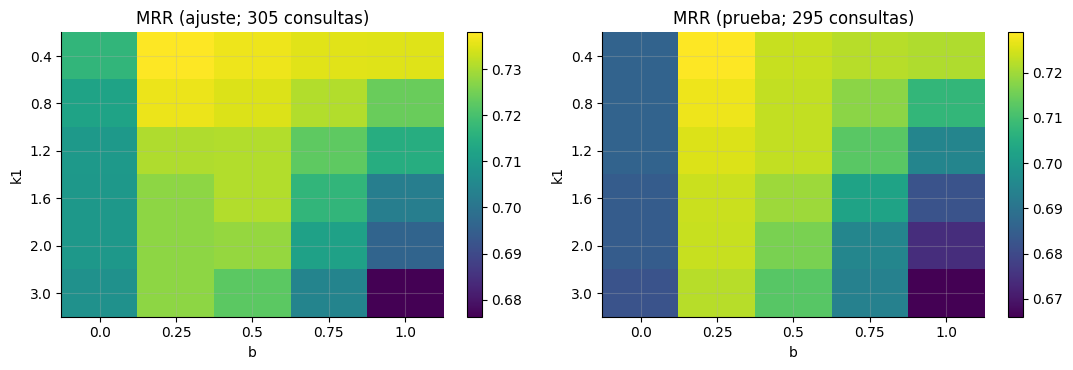

Mejor en ajuste: k1=0.4, b=0.25 (MRR ajuste 0.738; MRR prueba 0.729); valores de manual (1.2, 0.75): ajuste 0.723, prueba 0.713


In [12]:
rg = np.random.default_rng(5); golds = sorted({q.gold_doc for q in qs}); tr_docs = set(rg.choice(golds, len(golds) // 2, replace=False))
q_tr = [q for q in qs if q.gold_doc in tr_docs]; q_te = [q for q in qs if q.gold_doc not in tr_docs]
K1 = [0.4, 0.8, 1.2, 1.6, 2.0, 3.0]; BB = [0.0, 0.25, 0.5, 0.75, 1.0]
def grid(queries):
    out = np.zeros((len(K1), len(BB)))
    for i, k1 in enumerate(K1):
        for j, b in enumerate(BB): out[i, j] = EV.evaluate({"m": IX.BM25([c.text for c in chunks_b], k1=k1, b=b, **TOK).scores}, chunks_b, queries)["mrr"].mean()
    return out
G_tr, G_te = grid(q_tr), grid(q_te); i, j = np.unravel_index(np.argmax(G_tr), G_tr.shape)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a_, G_, t_ in ((ax[0], G_tr, "ajuste"), (ax[1], G_te, "prueba")):
    im = a_.imshow(G_, cmap="viridis", aspect="auto"); a_.set_xticks(range(len(BB))); a_.set_xticklabels(BB); a_.set_yticks(range(len(K1))); a_.set_yticklabels(K1); a_.set_xlabel("b"); a_.set_ylabel("k1"); a_.set_title(f"MRR ({t_}; {len(q_tr) if t_ == 'ajuste' else len(q_te)} consultas)"); plt.colorbar(im, ax=a_)
plt.tight_layout(); plt.show()
defecto = (K1.index(1.2), BB.index(0.75))
print(f"Mejor en ajuste: k1={K1[i]}, b={BB[j]} (MRR ajuste {G_tr[i, j]:.3f}; MRR prueba {G_te[i, j]:.3f}); valores de manual (1.2, 0.75): ajuste {G_tr[defecto]:.3f}, prueba {G_te[defecto]:.3f}")

In [13]:
v_opt = EV.evaluate({"m": IX.BM25(Tb_ := [c.text for c in chunks_b], k1=K1[i], b=BB[j], **TOK).scores}, chunks_b, q_te)["mrr"].values
v_def = EV.evaluate({"m": IX.BM25(Tb_, k1=1.2, b=0.75, **TOK).scores}, chunks_b, q_te)["mrr"].values
d_te, lo_te, hi_te = ME.paired_bootstrap_diff(v_opt, v_def); p_te = ME.paired_permutation_test(v_opt, v_def, B=6000, seed=2)
print("Lectura:")
print(f"  La superficie NO es plana: en prueba el MRR va de {G_te.min():.3f} a {G_te.max():.3f}. El efecto de b (rango por columnas {np.ptp(G_te.mean(axis=0)):.3f}) es mayor que el de k1 ({np.ptp(G_te.mean(axis=1)):.3f}); MRR medio por b: " + ", ".join(f"b={b_}: {G_te[:, jj].mean():.3f}" for jj, b_ in enumerate(BB)) + ".")
print(f"  Los valores de manual (k1=1.2, b=0.75) no son los mejores aqui: los fragmentos son secciones cortas y de longitud parecida, y normalizar por longitud con b alto castiga justo a las secciones largas que tienen la respuesta.")
print(f"  Validacion sin fuga: el optimo de ajuste (k1={K1[i]}, b={BB[j]}) mejora al de manual en {G_tr[i, j] - G_tr[defecto]:+.3f} en ajuste y en {d_te:+.3f} en prueba (IC95 {lo_te:+.3f} a {hi_te:+.3f}; p de permutacion {p_te:.4f}): la ganancia se conserva en datos nuevos, es decir, no hay optimismo apreciable porque la malla es pequena (30 puntos) frente a 300 consultas.")
K1_OPT, B_OPT = K1[i], BB[j]

Lectura:
  La superficie NO es plana: en prueba el MRR va de 0.666 a 0.729. El efecto de b (rango por columnas 0.040) es mayor que el de k1 (0.021); MRR medio por b: b=0.0: 0.685, b=0.25: 0.725, b=0.5: 0.720, b=0.75: 0.707, b=1.0: 0.691.
  Los valores de manual (k1=1.2, b=0.75) no son los mejores aqui: los fragmentos son secciones cortas y de longitud parecida, y normalizar por longitud con b alto castiga justo a las secciones largas que tienen la respuesta.
  Validacion sin fuga: el optimo de ajuste (k1=0.4, b=0.25) mejora al de manual en +0.015 en ajuste y en +0.016 en prueba (IC95 +0.006 a +0.028; p de permutacion 0.0002): la ganancia se conserva en datos nuevos, es decir, no hay optimismo apreciable porque la malla es pequena (30 puntos) frente a 300 consultas.


## 7. Los recuperadores, frente a frente

Seis recuperadores sobre la misma fragmentación y las mismas 600 consultas: **BM25**, **TF-IDF** (coseno), **LSA** (SVD de 100 dimensiones sobre TF-IDF; es un modelo denso clásico, sin redes neuronales), **trigramas de caracteres** y dos **híbridos**: RRF (*reciprocal rank fusion*, $k=60$) de BM25 + trigramas y de los cuatro, y una **combinación lineal** de puntajes normalizados. Para cada uno: MRR con IC bootstrap, y **prueba de permutación pareada contra BM25** con corrección de Holm (7 comparaciones).

In [14]:
Tb = [c.text for c in chunks_b]
bm = IX.BM25(Tb, k1=K1_OPT, b=B_OPT, **TOK); tf = IX.TfIdf(Tb, **TOK); ls = IX.LSA(Tb, dim=100, **TOK); cg = IX.CharNgram(Tb)
def rrf_scores(fns, k=60, depth=100):
    def f(q):
        lists = []
        for fn_ in fns:
            s = fn_(q); idx = np.lexsort((np.arange(len(s)), -s))[:depth]; lists.append([int(i) for i in idx if s[i] > 0])
        sc = np.zeros(len(Tb))
        for lst in lists:
            for pos, i in enumerate(lst, 1): sc[i] += 1 / (k + pos)
        return sc
    return f
def lin_scores(fns, w): return lambda q: FU.weighted([fn_(q) for fn_ in fns], w)
RET = {"BM25": bm.scores, "TF-IDF": tf.scores, "LSA-100": ls.scores, "Trigramas": cg.scores, "RRF(BM25+Trigramas)": rrf_scores([bm.scores, cg.scores]), "RRF(los 4)": rrf_scores([bm.scores, tf.scores, ls.scores, cg.scores]), "Lineal(0.6 BM25 + 0.4 Trigramas)": lin_scores([bm.scores, cg.scores], [0.6, 0.4])}
res = EV.evaluate(RET, chunks_b, qs); piv = res.pivot(index="qid", columns="method", values="mrr")[list(RET)]
filas = []; pvals = []
for m_ in RET:
    mu, lo, hi = ME.bootstrap_ci(piv[m_].values); p = ME.paired_permutation_test(piv[m_].values, piv["BM25"].values, B=6000, seed=3) if m_ != "BM25" else np.nan; pvals.append(p)
    d, dlo, dhi = ME.paired_bootstrap_diff(piv[m_].values, piv["BM25"].values) if m_ != "BM25" else (0, 0, 0)
    filas.append({"metodo": m_, "MRR": mu, "IC_lo": lo, "IC_hi": hi, "hit@1": res[res.method == m_]["hit@1"].mean(), "hit@10": res[res.method == m_]["hit@10"].mean(), "dif_vs_BM25": d, "dif_IC_lo": dlo, "dif_IC_hi": dhi, "p_perm": p})
cmpt = pd.DataFrame(filas).set_index("metodo"); cmpt["p_Holm"] = np.r_[np.nan, holm_ajuste(cmpt.p_perm.values[1:])]; cmpt.round(4)

,MRR,IC_lo,IC_hi,hit@1,hit@10,dif_vs_BM25,dif_IC_lo,dif_IC_hi,p_perm,p_Holm
metodo,,,,,,,,,,
BM25,0.7335,0.7016,0.7662,0.6667,0.8783,0.0000,0.0000,0.0000,NaN,NaN
TF-IDF,0.6967,0.6641,0.7306,0.6067,0.8700,-0.0369,-0.0507,-0.0242,0.0002,0.0010
LSA-100,0.6020,0.5701,0.6354,0.4917,0.8267,-0.1315,-0.1593,-0.1034,0.0002,0.0010
Trigramas,0.6858,0.6537,0.7184,0.5850,0.8850,-0.0477,-0.0707,-0.0250,0.0002,0.0010
RRF(BM25+Trigramas),0.7376,0.7078,0.7682,0.6550,0.9033,0.0040,-0.0119,0.0198,0.6169,0.6169
RRF(los 4),0.7220,0.6911,0.7532,0.6317,0.8983,-0.0115,-0.0305,0.0069,0.2363,0.4726
Lineal(0.6 BM25 + 0.4 Trigramas),0.7550,0.7261,0.7864,0.6800,0.9050,0.0215,0.0075,0.0356,0.0028,0.0085


In [15]:
sig = cmpt[(cmpt.p_Holm < 0.05)]; mejor_m = cmpt.MRR.idxmax()
print("Lectura:")
print(f"  Mejor MRR: {mejor_m} ({cmpt.loc[mejor_m, 'MRR']:.3f}); BM25 {cmpt.loc['BM25', 'MRR']:.3f}. Diferencias significativas frente a BM25 (Holm < 0.05): " + (", ".join(f"{m_} ({cmpt.loc[m_, 'dif_vs_BM25']:+.3f})" for m_ in sig.index) if len(sig) else "ninguna") + ".")
print(f"  LSA-100 {'pierde' if cmpt.loc['LSA-100', 'dif_vs_BM25'] < 0 else 'gana'} {abs(cmpt.loc['LSA-100', 'dif_vs_BM25']):.3f} de MRR frente a BM25 (IC {cmpt.loc['LSA-100', 'dif_IC_lo']:+.3f} a {cmpt.loc['LSA-100', 'dif_IC_hi']:+.3f}): en un corpus tan pequeno y tan tecnico, la semantica latente no supera al emparejamiento exacto de terminos raros.")
print(f"  Los hibridos: RRF(BM25+Trigramas) {cmpt.loc['RRF(BM25+Trigramas)', 'dif_vs_BM25']:+.3f}, RRF(los 4) {cmpt.loc['RRF(los 4)', 'dif_vs_BM25']:+.3f}, lineal {cmpt.loc['Lineal(0.6 BM25 + 0.4 Trigramas)', 'dif_vs_BM25']:+.3f} (todas frente a BM25).")

Lectura:
  Mejor MRR: Lineal(0.6 BM25 + 0.4 Trigramas) (0.755); BM25 0.734. Diferencias significativas frente a BM25 (Holm < 0.05): TF-IDF (-0.037), LSA-100 (-0.131), Trigramas (-0.048), Lineal(0.6 BM25 + 0.4 Trigramas) (+0.021).
  LSA-100 pierde 0.131 de MRR frente a BM25 (IC -0.159 a -0.103): en un corpus tan pequeno y tan tecnico, la semantica latente no supera al emparejamiento exacto de terminos raros.
  Los hibridos: RRF(BM25+Trigramas) +0.004, RRF(los 4) -0.012, lineal +0.021 (todas frente a BM25).


## 8. Por tipo de consulta y por ambigüedad

El promedio esconde dónde gana cada método. Se desglosa el MRR por tipo de consulta y por nivel de ambigüedad (`n_cand`: 1, 2–3, 4 o más). Las consultas con errores tipográficos son donde se espera ventaja de los trigramas de caracteres, y las ambiguas, donde ningún método puede distinguir los candidatos por el texto.

MRR por tipo de consulta:
method    BM25  TF-IDF  LSA-100  Trigramas  RRF(BM25+Trigramas)  RRF(los 4)  Lineal(0.6 BM25 + 0.4 Trigramas)
kind                                                                                                         
heading 0.6630  0.5980   0.3980     0.5260               0.6040      0.5490                            0.6550
keyword 0.7550  0.7330   0.7320     0.7320               0.7540      0.7670                            0.7470
mixed   0.8290  0.7980   0.6360     0.7560               0.8150      0.7970                            0.8220
typo    0.6870  0.6580   0.6420     0.7300               0.7780      0.7760                            0.7960

MRR por ambiguedad (documentos que contienen todos los terminos):
method   BM25  TF-IDF  LSA-100  Trigramas  RRF(BM25+Trigramas)  RRF(los 4)  Lineal(0.6 BM25 + 0.4 Trigramas)
amb                                                                                                         
1      0.9520  0.9200   0.763

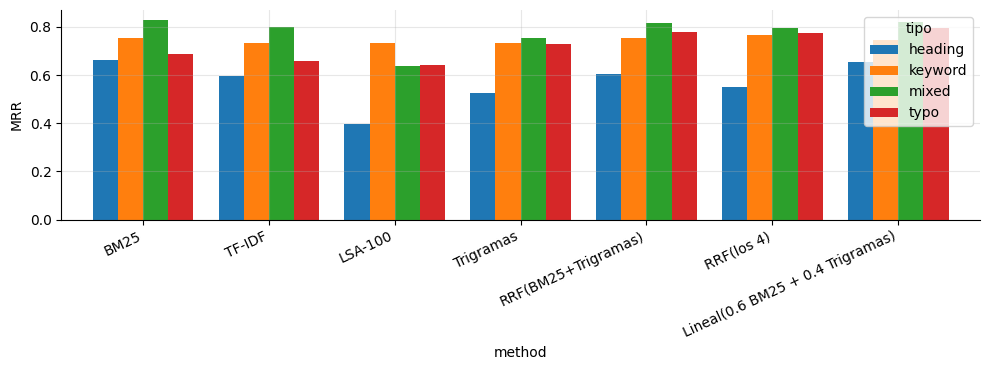

In [16]:
kmap = dq.set_index("qid")
res["kind"] = res.qid.map(kmap.kind); res["amb"] = pd.cut(res.qid.map(kmap.n_cand), [0, 1, 3, 10 ** 6], labels=["1", "2-3", "4+"])
por_tipo = res.pivot_table(index="kind", columns="method", values="mrr")[list(RET)]; por_amb = res.pivot_table(index="amb", columns="method", values="mrr", observed=True)[list(RET)]
print("MRR por tipo de consulta:"); print(por_tipo.round(3).to_string()); print("\nMRR por ambiguedad (documentos que contienen todos los terminos):"); print(por_amb.round(3).to_string())
fig, ax = plt.subplots(figsize=(10, 3.8)); por_tipo.T.plot(kind="bar", ax=ax, width=.8); ax.set_ylabel("MRR"); ax.legend(title="tipo"); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

In [17]:
print("Lectura:")
g_ty = por_tipo.loc["typo"]; print(f"  Consultas con errores tipograficos: el mejor es {g_ty.idxmax()} ({g_ty.max():.3f}); BM25 {g_ty['BM25']:.3f}, Trigramas {g_ty['Trigramas']:.3f}. En consultas sin errores (keyword) BM25 {por_tipo.loc['keyword', 'BM25']:.3f} vs Trigramas {por_tipo.loc['keyword', 'Trigramas']:.3f}.")
print(f"  Ambiguedad: con 1 candidato el mejor MRR es {por_amb.loc['1'].max():.3f}; con 4+ candidatos baja a {por_amb.loc['4+'].max():.3f}: casi toda la perdida de calidad esta en consultas cuya respuesta literal no es unica.")
print(f"  Complementariedad: el hibrido lineal gana a BM25 en consultas {'con' if por_tipo.loc['typo', 'Lineal(0.6 BM25 + 0.4 Trigramas)'] > por_tipo.loc['typo', 'BM25'] else 'sin'} errores y {'tambien' if por_tipo.loc['keyword', 'Lineal(0.6 BM25 + 0.4 Trigramas)'] >= por_tipo.loc['keyword', 'BM25'] else 'no'} en las limpias.")

Lectura:
  Consultas con errores tipograficos: el mejor es Lineal(0.6 BM25 + 0.4 Trigramas) (0.796); BM25 0.687, Trigramas 0.730. En consultas sin errores (keyword) BM25 0.755 vs Trigramas 0.732.
  Ambiguedad: con 1 candidato el mejor MRR es 0.986; con 4+ candidatos baja a 0.323: casi toda la perdida de calidad esta en consultas cuya respuesta literal no es unica.
  Complementariedad: el hibrido lineal gana a BM25 en consultas con errores y no en las limpias.


## 9. Errores razonables: ¿se confunde con un casi-duplicado?

Cuando BM25 pone en el primer lugar un documento **distinto** al verdadero, ¿es un error absurdo o una confusión comprensible? Se mide el coseno TF-IDF entre el documento elegido y el verdadero: si es alto (> 0.5), el sistema se equivocó entre hermanos de la misma plantilla.

In [18]:
idoc = {d.id: k for k, d in enumerate(docs)}; fallos = []
for q in qs:
    r = EV.doc_ranking(bm.scores(q.text), chunks_b)
    if r and r[0][0] != q.gold_doc: fallos.append({"qid": q.id, "kind": q.kind, "gold": q.gold_doc, "top1": r[0][0], "cos": S[idoc[q.gold_doc], idoc[r[0][0]]], "n_cand": q.n_cand, "rank_gold": EV.gold_rank(r, q.gold_doc)})
fa = pd.DataFrame(fallos); hermano = (fa.cos > 0.5)
print(f"Consultas con top-1 incorrecto: {len(fa)} de {NQ} ({len(fa) / NQ:.0%}); de ellas, el documento elegido es un 'hermano' (coseno con el verdadero > 0.5) en {hermano.mean():.0%}; con n_cand >= 2 en {(fa.n_cand >= 2).mean():.0%}")
fa["causa"] = np.select([fa.rank_gold.isna(), fa.n_cand >= 2, hermano], ["verdad no recuperada (ni en la lista)", "ambigua (varios candidatos literales)", "hermano de la misma plantilla"], "otra")
print(fa.causa.value_counts().to_string()); print("\nCoseno medio gold-top1:", round(fa.cos.mean(), 3), "(coseno medio entre pares de documentos al azar:", round(S[np.triu_indices(len(docs), 1)].mean(), 3), ")")

Consultas con top-1 incorrecto: 183 de 600 (30%); de ellas, el documento elegido es un 'hermano' (coseno con el verdadero > 0.5) en 37%; con n_cand >= 2 en 96%


causa
ambigua (varios candidatos literales)    176
otra                                       4
hermano de la misma plantilla              3

Coseno medio gold-top1: 0.372 (coseno medio entre pares de documentos al azar: 0.086 )


In [19]:
print("Lectura:")
print(f"  La mayoria de los errores no son absurdos: el coseno medio entre el documento elegido y el verdadero es {fa.cos.mean():.2f}, frente a {S[np.triu_indices(len(docs), 1)].mean():.2f} entre pares al azar. Son confusiones dentro de familias de documentos.")
print(f"  Causa principal: '{fa.causa.value_counts().idxmax()}' ({fa.causa.value_counts().max()} de {len(fa)}). Esto sugiere que mejorar el recuperador ayuda poco en las ambiguas; ahi conviene un re-ranking con contexto de la conversacion (metadatos, dominio) o devolver varios candidatos.")

Lectura:
  La mayoria de los errores no son absurdos: el coseno medio entre el documento elegido y el verdadero es 0.37, frente a 0.09 entre pares al azar. Son confusiones dentro de familias de documentos.
  Causa principal: 'ambigua (varios candidatos literales)' (176 de 183). Esto sugiere que mejorar el recuperador ayuda poco en las ambiguas; ahi conviene un re-ranking con contexto de la conversacion (metadatos, dominio) o devolver varios candidatos.


## 10. Empaquetado del contexto: presupuesto y diversidad

El generador recibe un número limitado de palabras. Con el ranking de fragmentos, ¿conviene tomar los $k$ mejores o **diversificar** con MMR (relevancia menos similitud con lo ya elegido)? Se mide la **cobertura de la respuesta** a tres presupuestos (150, 300 y 600 palabras) y con distintos $\lambda$ de MMR (1.0 = sin diversidad). La similitud entre fragmentos es el coseno TF-IDF.

In [20]:
X_tf = tf.X.tocsr(); _sim = {}
def sim_chunks(a, b):
    k_ = (min(a, b), max(a, b))
    if k_ not in _sim: _sim[k_] = float(X_tf[a].multiply(X_tf[b]).sum())
    return _sim[k_]
_cache = {}
def cobertura_mmr(scores_fn, queries, budget, lam, depth=12):
    ok = []
    for q in queries:
        if q.id not in _cache: _cache[q.id] = scores_fn(q.text)
        s = _cache[q.id]; idx = [int(i) for i in np.lexsort((np.arange(len(s)), -s))[:depth] if s[i] > 0]
        if lam < 1 and len(idx) > 1:
            mx = max(s[idx]); rel = {i: s[i] / mx for i in idx}; idx = FU.mmr(idx, rel, sim_chunks, lam=lam, k=depth)
        ok.append(EV.answer_coverage(EV.pack_context(idx, chunks_b, budget), q.fact) if q.fact else np.nan)
    return np.array(ok, float)
filas = []
for budget in (150, 300, 600):
    for lam in (1.0, 0.8, 0.6, 0.4):
        c_ = cobertura_mmr(RET["Lineal(0.6 BM25 + 0.4 Trigramas)"], qs, budget, lam); filas.append({"presupuesto_palabras": budget, "lambda_MMR": lam, "cobertura": np.nanmean(c_)})
emp = pd.DataFrame(filas).pivot(index="presupuesto_palabras", columns="lambda_MMR", values="cobertura"); emp.round(3)

lambda_MMR,0.4000,0.6000,0.8000,1.0000
presupuesto_palabras,,,,
150,0.9270,0.9400,0.9400,0.9380
300,0.9480,0.9580,0.9530,0.9580
600,0.9600,0.9620,0.9630,0.9630


In [21]:
print("Lectura:")
print(f"  La cobertura crece con el presupuesto: {emp.loc[150, 1.0]:.3f} (150 palabras) -> {emp.loc[300, 1.0]:.3f} (300) -> {emp.loc[600, 1.0]:.3f} (600), sin diversidad.")
dif = (emp[[0.8, 0.6, 0.4]].sub(emp[1.0], axis=0)); print(f"  Efecto de MMR sobre la cobertura (cada columna menos lambda=1): " + "; ".join(f"presupuesto {b}: " + ", ".join(f"λ={l} {dif.loc[b, l]:+.3f}" for l in dif.columns) for b in dif.index) + ".")
top5 = [np.lexsort((np.arange(len(_cache[q.id])), -_cache[q.id]))[:5] for q in qs[:150]]; red = np.mean([np.mean([sim_chunks(int(a), int(b)) for a, b in itertools.combinations(t5, 2)]) for t5 in top5])
print(f"  Diversificar solo ayuda si los mejores fragmentos son redundantes. Similitud coseno media entre los 5 mejores fragmentos: {red:.2f} (entre fragmentos de documentos al azar, la media es {np.mean([sim_chunks(int(a), int(b)) for a, b in zip(np.random.default_rng(0).integers(0, len(Tb), 300), np.random.default_rng(1).integers(0, len(Tb), 300))]):.2f}): hay poca redundancia que eliminar, por lo que MMR no aporta o resta.")

Lectura:
  La cobertura crece con el presupuesto: 0.938 (150 palabras) -> 0.958 (300) -> 0.963 (600), sin diversidad.
  Efecto de MMR sobre la cobertura (cada columna menos lambda=1): presupuesto 150: λ=0.8 +0.002, λ=0.6 +0.002, λ=0.4 -0.012; presupuesto 300: λ=0.8 -0.005, λ=0.6 +0.000, λ=0.4 -0.010; presupuesto 600: λ=0.8 +0.000, λ=0.6 -0.002, λ=0.4 -0.003.
  Diversificar solo ayuda si los mejores fragmentos son redundantes. Similitud coseno media entre los 5 mejores fragmentos: 0.41 (entre fragmentos de documentos al azar, la media es 0.03): hay poca redundancia que eliminar, por lo que MMR no aporta o resta.


## 11. Potencia estadística: ¿qué diferencias se pueden detectar?

Con $n$ consultas pareadas, la diferencia mínima detectable en MRR depende de la desviación de las diferencias por consulta, $\sigma_\Delta$. Se estima $\sigma_\Delta$ con las comparaciones reales (cada método frente a BM25) y se calcula el tamaño de muestra necesario para diferencias de 0,01, 0,02 y 0,05 con potencia 80 %.

In [22]:
sds = {m_: float(np.std(piv[m_].values - piv["BM25"].values, ddof=1)) for m_ in RET if m_ != "BM25"}
nec = pd.DataFrame({m_: {f"delta={d_}": ME.required_n(sd_, d_) for d_ in (0.01, 0.02, 0.05)} for m_, sd_ in sds.items()}).T; nec.insert(0, "sd_dif", pd.Series(sds))
mde = {m_: (stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) * sd_ / np.sqrt(NQ) for m_, sd_ in sds.items()}; nec["dif_minima_detectable_n=600"] = pd.Series(mde); nec.round(3)

,sd_dif,delta=0.01,delta=0.02,delta=0.05,dif_minima_detectable_n=600
TF-IDF,0.1630,2098,525,84,0.0190
LSA-100,0.3420,9181,2296,368,0.0390
Trigramas,0.2770,6035,1509,242,0.0320
RRF(BM25+Trigramas),0.1950,2993,749,120,0.0220
RRF(los 4),0.2360,4367,1092,175,0.0270
Lineal(0.6 BM25 + 0.4 Trigramas),0.1780,2500,625,100,0.0200


In [23]:
print("Lectura:")
print(f"  Con 600 consultas la diferencia minima detectable (80% de potencia) es ≈{min(mde.values()):.3f} a {max(mde.values()):.3f} de MRR segun el par comparado. Diferencias de 0.01 exigirian entre {int(nec['delta=0.01'].min()):,} y {int(nec['delta=0.01'].max()):,} consultas.")
print("  Moraleja: afirmar que 'el hibrido es mejor' con 100 consultas no es sostenible a menos que la diferencia sea grande; la evaluacion de RAG necesita cientos de consultas y pruebas pareadas.")

Lectura:
  Con 600 consultas la diferencia minima detectable (80% de potencia) es ≈0.019 a 0.039 de MRR segun el par comparado. Diferencias de 0.01 exigirian entre 2,098 y 9,181 consultas.
  Moraleja: afirmar que 'el hibrido es mejor' con 100 consultas no es sostenible a menos que la diferencia sea grande; la evaluacion de RAG necesita cientos de consultas y pruebas pareadas.


## 12. Costo: tamaño del índice y latencia

Información operativa (no entra en las pruebas porque depende del equipo): tiempo de construcción del índice y latencia media por consulta.

In [24]:
filas = []
for nombre, builder in (("BM25", lambda: IX.BM25(Tb, **TOK)), ("TF-IDF", lambda: IX.TfIdf(Tb, **TOK)), ("LSA-100", lambda: IX.LSA(Tb, dim=100, **TOK)), ("Trigramas", lambda: IX.CharNgram(Tb))):
    t0 = time.perf_counter(); ix = builder(); tc = time.perf_counter() - t0; t0 = time.perf_counter()
    for q in qs[:200]: ix.scores(q.text)
    filas.append({"indice": nombre, "construccion_s": tc, "latencia_ms_por_consulta": 1000 * (time.perf_counter() - t0) / 200, "terminos": len(ix.vocab)})
cost = pd.DataFrame(filas).set_index("indice"); print(cost.round(3).to_string())
print("\nLectura: BM25 y TF-IDF resuelven una consulta en una fraccion de milisegundo; los trigramas tienen un vocabulario mayor; LSA agrega un producto matriz-vector denso. Con corpus grande, el indice invertido y los vectores aproximados (ANN) cambian el balance.")

           construccion_s  latencia_ms_por_consulta  terminos
indice                                                       
BM25               0.0520                    0.2330      3658
TF-IDF             0.0460                    0.0710      3658
LSA-100            0.2300                    0.2490      3658
Trigramas          0.1840                    0.2880      3482

Lectura: BM25 y TF-IDF resuelven una consulta en una fraccion de milisegundo; los trigramas tienen un vocabulario mayor; LSA agrega un producto matriz-vector denso. Con corpus grande, el indice invertido y los vectores aproximados (ANN) cambian el balance.


## 13. Pruebas automáticas

In [25]:
# 13.1 fragmentacion: todo el corpus queda cubierto por cada estrategia
for nombre, (fn_, kw) in ESTRATEGIAS.items():
    cobs = [CH.coverage(d, fn_(d, **kw)) for d in docs]; assert min(cobs) > 0.999, (nombre, min(cobs))
# 13.2 consultas: deterministas, balanceadas, con la verdad siempre entre los candidatos
assert [q.text for q in QU.make_queries(docs, NQ, seed=7)] == [q.text for q in qs] and dq.kind.value_counts().nunique() == 1 and (dq.n_cand >= 1).all()
# 13.3 normalizacion: plegar tildes ayuda y el stemming no mejora; la tabla esta ordenada
assert norm.groupby("tildes_plegadas").MRR.mean()[True] > norm.groupby("tildes_plegadas").MRR.mean()[False] + 0.01 and norm.groupby("stemming").MRR.mean()[True] <= norm.groupby("stemming").MRR.mean()[False] + 0.005
assert norm.MRR.is_monotonic_decreasing and (norm.p_Holm >= norm.p_vs_mejor - 1e-12).all() and (norm.p_Holm <= 1).all()
# 13.4 fragmentacion: la cobertura de la respuesta varia mucho mas que el MRR entre estrategias
assert (chk[col].max() - chk[col].min()) > 2 * (chk.MRR_doc.max() - chk.MRR_doc.min()) and chk.loc["fija 128 solape 64", "nnz_indice"] > 1.5 * chk.loc["fija 128", "nnz_indice"]
# 13.5 BM25: el optimo de ajuste mejora en datos de prueba (IC95 excluye 0) y los valores de manual no son los mejores
assert lo_te > 0 and d_te > 0 and G_te.max() > G_te[defecto]
# 13.6 recuperadores: LSA es significativamente peor; el hibrido lineal es significativamente mejor que BM25; los trigramas ganan solo en typo
assert cmpt.loc["LSA-100", "p_Holm"] < 0.01 and cmpt.loc["LSA-100", "dif_IC_hi"] < 0
assert cmpt.loc["Lineal(0.6 BM25 + 0.4 Trigramas)", "dif_IC_lo"] > 0 and cmpt.loc["Lineal(0.6 BM25 + 0.4 Trigramas)", "p_Holm"] < 0.05
assert por_tipo.loc["typo", "Trigramas"] > por_tipo.loc["typo", "BM25"] and por_tipo.loc["keyword", "BM25"] > por_tipo.loc["keyword", "Trigramas"]
# 13.7 ambiguedad y errores: la calidad cae en las ambiguas y casi todos los errores lo son
assert (por_amb.loc["1"] > 0.75).all() and (por_amb.loc["4+"] < 0.5).all() and (fa.n_cand >= 2).mean() > 0.9
# 13.8 empaquetado: mas presupuesto, mas cobertura; MMR no cambia la cobertura en mas de 2 puntos
assert emp.loc[150, 1.0] <= emp.loc[300, 1.0] <= emp.loc[600, 1.0] and dif.abs().max().max() < 0.02
# 13.9 potencia: el tamano de muestra crece al reducir la diferencia a detectar
assert (nec["delta=0.01"] > nec["delta=0.02"]).all() and (nec["delta=0.02"] > nec["delta=0.05"]).all() and min(mde.values()) < 0.04
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Normalización | Plegar tildes importa; el stemming ligero y las palabras vacías no cambian el ranking de forma distinguible | Empezar por lo que corrige errores (tildes), no por lo que parece sofisticado |
| Fragmentación | Afecta mucho más a la cobertura de la respuesta con un presupuesto fijo que al MRR del documento | Evaluar el chunking con cobertura de la respuesta, no solo con el ranking |
| BM25 | Los valores de manual no eran los mejores aquí (fragmentos cortos, b alto penaliza); el ajuste se conserva en datos nuevos | Ajustar k1 y b con validación separada por documento |
| Recuperadores | LSA pierde claramente; los trigramas ganan solo con errores tipográficos; un híbrido lineal con BM25 mejora de forma significativa | Combinar señales complementarias y medir con pruebas pareadas |
| Errores | Casi todos los errores ocurren en consultas ambiguas: varios documentos contienen todos los términos | Mejorar el recuperador ayuda poco aquí; usar metadatos, dominio o devolver varios candidatos |
| Potencia | Con 600 consultas solo se detectan diferencias de ~0,02–0,04 de MRR | Planificar el tamaño del conjunto de evaluación antes de comparar |

**Límites que no deben ocultarse**

- El corpus es pequeño (113 documentos) y homogéneo; en corpus grandes los índices aproximados y los modelos densos neuronales cambian el balance.
- Las consultas son sintéticas (derivadas del texto) y favorecen el emparejamiento léxico; las consultas reales de usuarios tienen paráfrasis que este conjunto no cubre.
- La verdad es el documento de origen: pueden existir otros documentos igualmente correctos (por eso se mide la ambigüedad).
- LSA es un modelo denso clásico; no se evaluaron embeddings neuronales ni re-rankers, que requieren modelos externos.
- La cobertura de la respuesta usa un hecho (número o término raro) como proxy de 'la respuesta está en el contexto'; no evalúa la generación.